In [1]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import nltk
from nltk.corpus import stopwords
import string
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pickle
from wordcloud import WordCloud

In [3]:
# Load dataset
df = pd.read_csv("/content/drive/MyDrive/DataSet/sms_spam_classifier/spam.csv", encoding="cp1252")

In [4]:
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
5163,ham,Ok leave no need to ask,NaN,NaN,NaN
1641,ham,"Hi , where are you? We're at and they're not ...",NaN,NaN,NaN
1717,spam,WOW! The Boys R Back. TAKE THAT 2007 UK Tour. ...,NaN,NaN,NaN
343,ham,Am not interested to do like that.,NaN,NaN,NaN
353,ham,Yo you guys ever figure out how much we need f...,NaN,NaN,NaN


In [5]:
df.shape

(5572, 5)

## 1. Data Cleaning

In [6]:
# Dataset info

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [7]:
# Drop last 3 cols
df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], inplace=True)

In [8]:
df.sample(5)

,v1,v2
3122,ham,He telling not to tell any one. If so treat fo...
1998,ham,"Well, I have to leave for my class babe ... Yo..."
1872,ham,Oh ok i didnt know what you meant. Yep i am ba...
5218,ham,I accidentally brought em home in the box
4250,ham,Omg Joanna is freaking me out. She's looked th...


In [9]:
# Rename Column
df.rename(columns={'v1': 'target', 'v2': 'text'}, inplace=True)
df.sample(5)


,target,text
4478,ham,Erutupalam thandiyachu
1196,ham,What he said is not the matter. My mind saying...
3529,ham,Tyler (getting an 8th) has to leave not long a...
1175,ham,Horrible u eat macs eat until u forgot abt me ...
493,ham,What class of &lt;#&gt; reunion?


In [10]:
# Encode label

# Initialize LabelEncoder to convert categorical target labels into numerical values
encoder = LabelEncoder()

# Fit the encoder and transform the target column into numeric class labels (0, 1, 2, ...)
df['target'] = encoder.fit_transform(df['target'])
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [11]:
# Check missing value

df.isnull().sum()

,0
target,0
text,0


In [12]:
# Check duplicate value
df.duplicated().sum()

np.int64(403)

In [13]:
# Remove duplicate rows from the DataFrame.
# keep='first' keeps the first occurrence of each duplicate row
# and removes all subsequent occurrences.

df = df.drop_duplicates(keep='first')
df.duplicated().sum()
df.shape

(5169, 2)

## 2. EDA


In [14]:
# Basic info
df['target'].value_counts()

,count
target,
0,4516
1,653


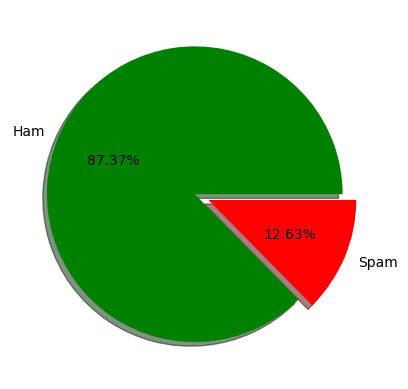

In [15]:
# Create a pie chart showing the distribution of Ham and Spam messages
plt.pie(
    df['target'].value_counts(),  # Count the number of messages in each class
    labels=['Ham', 'Spam'],        # Display class names on the pie chart
    autopct="%0.2f%%",            # Display percentages with 2 decimal places (e.g., 85.50%)
    colors=['green', 'red'],       # Set green for Ham and red for Spam
    explode=[0, 0.1],             # Keep the first slice normal (0) and move the second slice outward by 10% of the radius (0.1)
    shadow=True                   # Add a shadow effect to make the pie chart look 3D
)

plt.show()  # Display the pie chart

In [16]:
!pip install nltk

In [17]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [18]:
# Count the total number of characters in each text message,
# including letters, numbers, spaces, and punctuation.

df['num_char'] = df['text'].apply(len)

In [19]:
# Count the number of tokens (words and punctuation) in each text
df['num_words'] = df['text'].apply(lambda x: len(nltk.word_tokenize(x)))

In [20]:
df.head()

,target,text,num_char,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [21]:
# Count the number of words in each text and store the result in a new column
df['num_sentence'] = df['text'].apply(lambda x: len(nltk.word_tokenize(x)))
df.head()

,target,text,num_char,num_words,num_sentence
0,0,"Go until jurong point, crazy.. Available only ...",111,24,24
1,0,Ok lar... Joking wif u oni...,29,8,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,37
3,0,U dun say so early hor... U c already then say...,49,13,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,15


In [22]:
# Display descriptive statistics (count, mean, std, min, max, and quartiles)
# for the number of characters, words, and sentences in the dataset.

df[['num_char', 'num_words', 'num_sentence']].describe()

,num_char,num_words,num_sentence
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,18.455794
std,58.236293,13.324758,13.324758
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,9.000000
50%,60.000000,15.000000,15.000000
75%,117.000000,26.000000,26.000000
max,910.000000,220.000000,220.000000


In [23]:
# Ham message
# Display descriptive statistics for character, word, and sentence counts where target = 0
df[df['target'] == 0][['num_char', 'num_words', 'num_sentence']].describe()

,num_char,num_words,num_sentence
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,17.123782
std,56.358207,13.493970,13.493970
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,8.000000
50%,52.000000,13.000000,13.000000
75%,90.000000,22.000000,22.000000
max,910.000000,220.000000,220.000000


In [24]:
# Spam message
# Display descriptive statistics for character, word, and sentence counts where target = 1
df[df['target'] == 1][['num_char', 'num_words', 'num_sentence']].describe()

,num_char,num_words,num_sentence
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,27.667688
std,30.137753,7.008418,7.008418
min,13.000000,2.000000,2.000000
25%,132.000000,25.000000,25.000000
50%,149.000000,29.000000,29.000000
75%,157.000000,32.000000,32.000000
max,224.000000,46.000000,46.000000


<Figure size 1000x800 with 0 Axes>

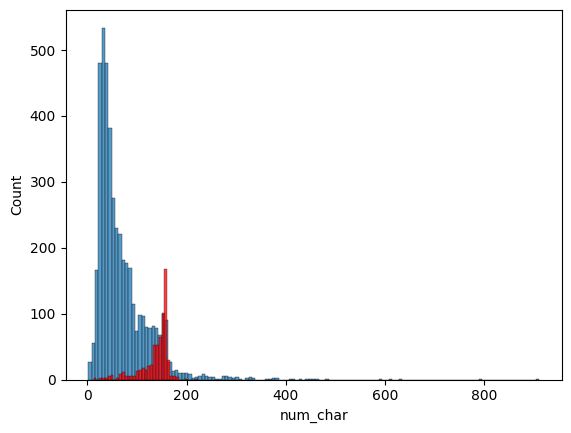

<Figure size 1000x800 with 0 Axes>

In [25]:
# Ham message
# Plot the character count distribution for Target 0
sns.histplot(df[df['target'] == 0]['num_char'])

# Spam message
# Plot the character count distribution for Target 1 in red
sns.histplot(df[df['target'] == 1]['num_char'], color='red')

plt.figure(figsize=(10, 8))

<Axes: xlabel='num_words', ylabel='Count'>

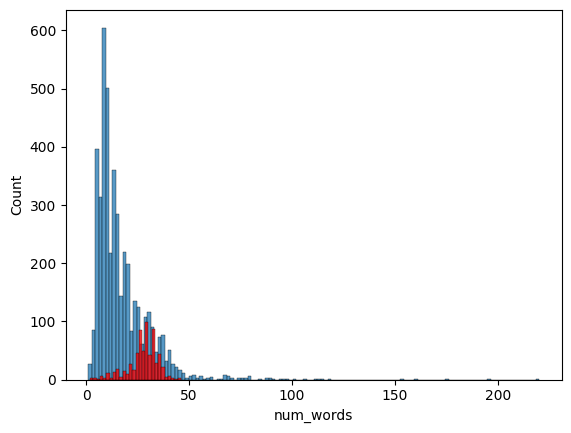

In [26]:
# Ham message
# Plot the word count distribution for Target 0
sns.histplot(df[df['target'] == 0]['num_words'])

# Spam message
# Plot the sentance count distribution for Target 1 in red
sns.histplot(df[df['target'] == 1]['num_words'], color='red')

<Axes: xlabel='num_sentence', ylabel='Count'>

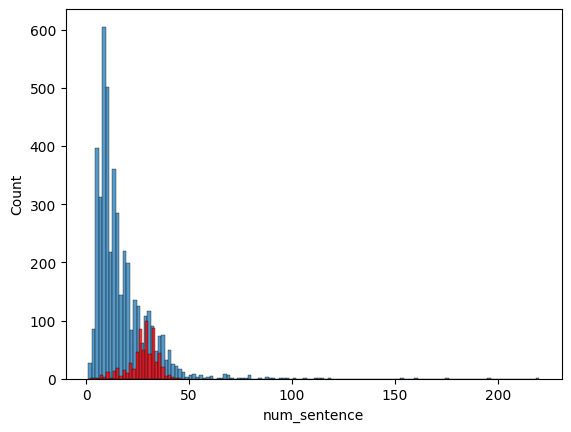

In [27]:
# Ham message
# Plot the sentance count distribution for Target 0
sns.histplot(df[df['target'] == 0]['num_sentence'])

# Spam message
# Plot the sentance count distribution for Target 1 in red
sns.histplot(df[df['target'] == 1]['num_sentence'], color='red')

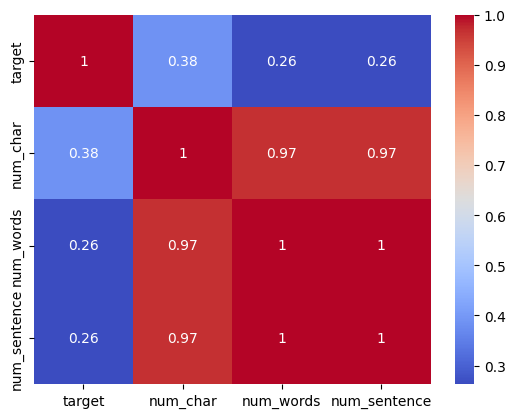

In [28]:
# Corelation using heatmap

# Select only numeric columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation
correlation = numeric_df.corr()

# Plot heatmap
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.show()

## 3. Data Preprocessing

In [29]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [30]:
ps = PorterStemmer()

In [31]:
def tansform_text(text):

    # Step 1: Convert all characters to lowercase
    text = text.lower()

    # Step 2: Tokenize the text into individual words and punctuation
    text = nltk.word_tokenize(text)

    # Step 3: Create an empty list to store filtered words
    y = []

    # Step 4: Remove punctuation and special characters
    # Keep only alphanumeric tokens (letters and numbers)
    for i in text:
        if i.isalnum():
            y.append(i)

    # Step 5: Copy filtered tokens into text
    text = y[:]

    # Step 6: Clear the list for the next filtering process
    y.clear()

    # Step 7: Remove English stopwords
    # Examples: is, am, are, the, a, an, in, on
    for i in text:
        if i not in stopwords.words('english'):
            y.append(i)
    # Step 8: Store the remaining words
    text = y[:]

    # Step 9: Clear the temporary list
    y.clear()

    # Loop through each word in the text
    for i in text:
      # Apply stemming to reduce each word to its root form
      y.append(ps.stem(i))

    # Join the stemmed words into a single string separated by spaces
    return " ".join(y)


In [32]:
df.head()

,target,text,num_char,num_words,num_sentence
0,0,"Go until jurong point, crazy.. Available only ...",111,24,24
1,0,Ok lar... Joking wif u oni...,29,8,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,37
3,0,U dun say so early hor... U c already then say...,49,13,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,15


In [43]:
# Apply the text preprocessing function to each row in the 'text' column
# and store the cleaned text in a new column called 'transform_text'
df['transform_text'] = df['text'].apply(tansform_text)

# Display the first 5 rows of the DataFrame
df.head()

,target,text,num_char,num_words,num_sentence,transform_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,24,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,8,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,37,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,13,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,15,nah think goe usf live around though


In [45]:
# Create a list of words from Ham messages
ham_word_list = []

for msg in df[df['target'] == 0]['transform_text'].dropna():
    ham_word_list.extend(msg.split())

# Create a list of words from Spam messages
spam_word_list = []

for msg in df[df['target'] == 1]['transform_text'].dropna():
    spam_word_list.extend(msg.split())

# Count the 30 most frequent words in Ham messages
ham_word_counts = Counter(ham_word_list).most_common(30)

# Count the 30 most frequent words in Spam messages
spam_word_counts = Counter(spam_word_list).most_common(30)

# Create separate DataFrames (do not overwrite original df)
ham_freq_df = pd.DataFrame(
    ham_word_counts,
    columns=['Word', 'Frequency']
)

spam_freq_df = pd.DataFrame(
    spam_word_counts,
    columns=['Word', 'Frequency']
)

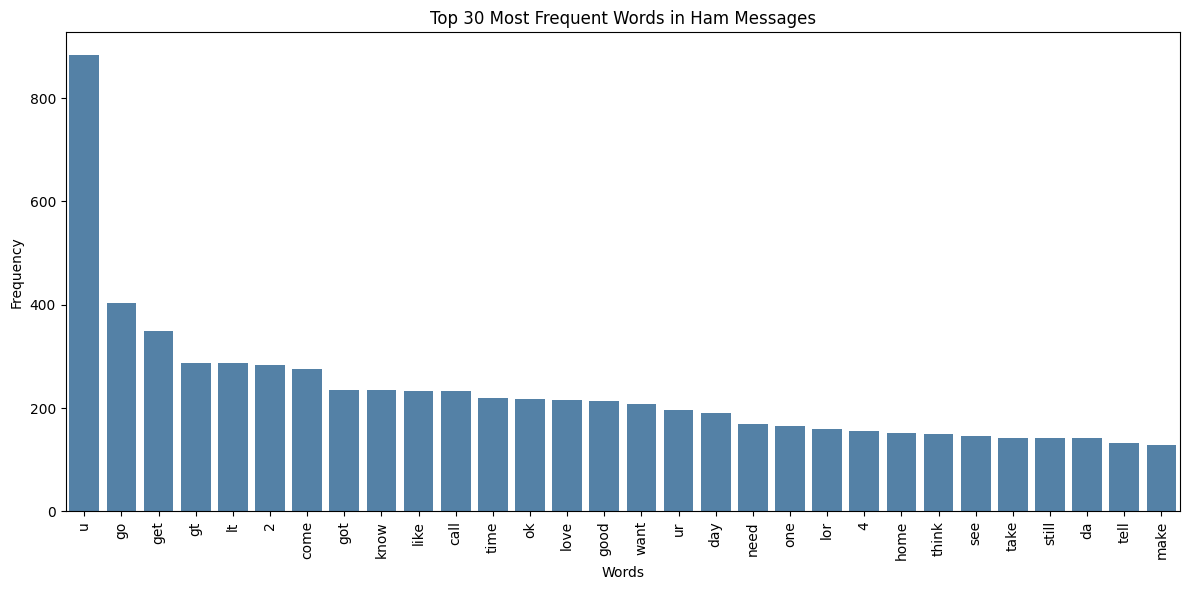

     Word  Frequency
0       u        883
1      go        404
2     get        349
3      gt        288
4      lt        287
5       2        284
6    come        275
7     got        236
8    know        236
9    like        234
10   call        233
11   time        219
12     ok        217
13   love        216
14   good        213
15   want        208
16     ur        197
17    day        190
18   need        170
19    one        165
20    lor        159
21      4        156
22   home        152
23  think        149
24    see        147
25   take        143
26  still        143
27     da        142
28   tell        133
29   make        129


In [48]:
# Create a bar chart for Ham messages
plt.figure(figsize=(12, 6))

sns.barplot(
    data=ham_freq_df,
    x='Word',
    y='Frequency',
    color='steelblue'
)

plt.xticks(rotation=90)
plt.title('Top 30 Most Frequent Words in Ham Messages')
plt.xlabel('Words')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

print(ham_freq_df)

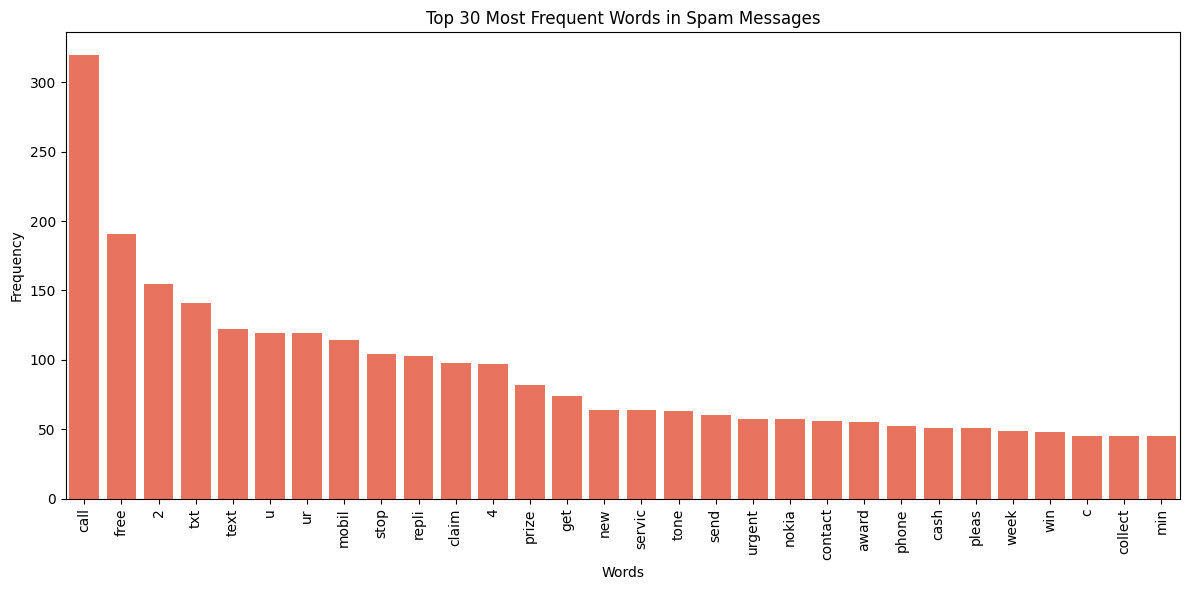

       Word  Frequency
0      call        320
1      free        191
2         2        155
3       txt        141
4      text        122
5         u        119
6        ur        119
7     mobil        114
8      stop        104
9     repli        103
10    claim         98
11        4         97
12    prize         82
13      get         74
14      new         64
15   servic         64
16     tone         63
17     send         60
18   urgent         57
19    nokia         57
20  contact         56
21    award         55
22    phone         52
23     cash         51
24    pleas         51
25     week         49
26      win         48
27        c         45
28  collect         45
29      min         45


In [50]:
# Create a bar chart for Spam messages
plt.figure(figsize=(12, 6))

sns.barplot(
    data=spam_freq_df,
    x='Word',
    y='Frequency',
    color='tomato'
)

plt.xticks(rotation=90)
plt.title('Top 30 Most Frequent Words in Spam Messages')
plt.xlabel('Words')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

print(spam_freq_df)

## 4. Build Model

In [51]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

cv = CountVectorizer()

In [56]:
# SMS messages have been represented using numerical features for machine learning.
X = cv.fit_transform(df['transform_text']).toarray()
X.shape

(5169, 6708)

In [57]:
# Display the vocabulary learned by CountVectorizer
print(cv.get_feature_names_out())

# Numeric Representation of 1st 5 sms
print(X[:5])

['008704050406' '0089' '0121' ... 'åôrent' 'ìä' 'ìï']
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [58]:
# Extracts the target labels (Ham or Spam) from your DataFrame and converts them into a NumPy array
y = df['target'].values
y

array([0, 0, 1, ..., 0, 0, 0], shape=(5169,))

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [64]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score

In [65]:
# Initialize three different Naive Bayes classifiers
gnb = GaussianNB()       # Gaussian Naive Bayes
mnb = MultinomialNB()    # Multinomial Naive Bayes
bnb = BernoulliNB()      # Bernoulli Naive Bayes


In [81]:
# ==========================================
# 1. Gaussian Naive Bayes
# ==========================================

# Train the Gaussian Naive Bayes model
# gnb.fit(X_train, y_train)

# # Predict labels for the test dataset
# y_pred_gnb = gnb.predict(X_test)

# # Evaluate model performance
# print("Gaussian Naive Bayes")
# print("Accuracy:", accuracy_score(y_test, y_pred_gnb))
# print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gnb))
# print("Precision:", precision_score(y_test, y_pred_gnb))

In [82]:
# ==========================================
# 2. Multinomial Naive Bayes
# ==========================================

# Train the Multinomial Naive Bayes model
# mnb.fit(X_train, y_train)

# # Predict labels using the trained Multinomial model
# y_pred_mnb = mnb.predict(X_test)

# # Evaluate model performance
# print("\nMultinomial Naive Bayes")
# print("Accuracy:", accuracy_score(y_test, y_pred_mnb))
# print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_mnb))
# print("Precision:", precision_score(y_test, y_pred_mnb))

In [84]:
# ==========================================
# Bernoulli Naive Bayes
# ==========================================

# Train the Bernoulli Naive Bayes model
bnb.fit(X_train, y_train)

# Predict labels for the test dataset
y_pred_bnb = bnb.predict(X_test)

# Evaluate model performance
print("\nBernoulli Naive Bayes")
print("Accuracy:", accuracy_score(y_test, y_pred_bnb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_bnb))
print("Precision:", precision_score(y_test, y_pred_bnb))


Bernoulli Naive Bayes
Accuracy: 0.9700193423597679
Confusion Matrix:
 [[893   3]
 [ 28 110]]
Precision: 0.9734513274336283


In [86]:
import pickle
from google.colab import files

# Save the trained Bernoulli Naive Bayes model
with open('bernoulli_nb.pkl', 'wb') as file:
    pickle.dump(bnb, file)

# Download the saved model
files.download('bernoulli_nb.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [87]:
# Save the trained CountVectorizer
with open('vectorizer.pkl', 'wb') as file:
    pickle.dump(cv, file)

# Download the vectorizer
files.download('vectorizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>